# Telco Churn — évaluer le risque sans surpromettre la décision
**Zaineb Mhiri · étude personnelle de portfolio**

Parcours : besoin → Gate 0 → DPD → compréhension → nettoyage → EDA décisionnelle → préparation → baseline/ML facultatif → évaluation/MRT → interprétation → recommandation → vérification.

Chaque opération importante suit HL : Contexte → Question → Notion → Risques → Mesure → Code → Lecture → Interprétation → Impact → Trace.
Le calcul est factorisé dans [src/analysis.py](../src/analysis.py) ; [la méthode](../docs/methodology.md) documente les choix et leurs limites.

Les modèles examinent une hypothèse de priorisation. Ce projet personnel a bénéficié d'une révision technique assistée pour la reproductibilité et la présentation. Il ne représente pas une mission client ni une certification de maîtrise professionnelle.

## 1 — Besoin client

**Problème de démonstration :** une équipe de fidélisation souhaite étudier comment prioriser des contacts limités.
**Valeur recherchée :** concentrer l'étude sur les profils à risque, puis vérifier qu'une intervention crée de la rétention rentable.
**Faits :** une cible de churn et des attributs clients sont disponibles.
**Hypothèses :** équipe CRM, contact de rétention, capacités 10/20/30 %.
**Manques :** aucun client réel, entretien, budget, offre ou coût attesté.

**Condition de sortie :** besoin formulé pour un benchmark pédagogique. Besoin client réel non validé ; aucune campagne réputée autorisée.

## 2 — Gate 0 : décision, décideur, risques, coûts d'erreur, refus

| Élément | État |
|---|---|
| Décision | Étudier une priorisation ; aucune campagne opérationnelle décidée |
| Décideur | Équipe CRM envisagée, pas un décideur client identifié |
| Risques | Sur-contact, churn manqué, offre inefficace, variable indisponible |
| Coûts FP/FN | Inconnus ; aucun coût « acceptable » supposé |
| Horizon / date de scoring | Non établis ; aucune prédiction future certifiée |
| Refus | STOP déploiement ; reporter le choix de campagne |

**Point de blocage obligatoire : Gate 0 n'est pas franchi pour agir.**
La suite est une analyse pédagogique limitée, demandée pour examiner la faisabilité, et non une recommandation d'action. Lever le blocage exige un vrai cadrage client.

## 3 — DPD : faisabilité avant l'analyse

| Critère | Observation préalable | Continuer / arrêter |
|---|---|---|
| Données avant décision | Pas de dates individuelles | STOP prédiction opérationnelle |
| Qualité / complétude | À vérifier aux étapes 4–5 | Diagnostic ; arrêter sur anomalie inexpliquée |
| Fuite | Cible et ID identifiables ; timing inconnu | Contrôler la préparation ; fuite temporelle non exclue |
| Représentativité | Aucun rapprochement avec une clientèle réelle | Limiter au benchmark |
| Effet de l'action | Aucun résultat de contact / offre | STOP promesse de rétention ou ROI |

**Verdict provisoire : PROMETTEUR pour étudier le classement ; STOP pour agir.**
Des données propres peuvent rester insuffisantes pour décider. Revenir au cadrage si le besoin exige une mesure de rentabilité.

## 4 — Data Understanding : source, sens et unités

**Contexte :** Un CSV pédagogique IBM est la seule source.

**Question :** Quel périmètre et quelle cible observe-t-on ?

**Notion :** Provenance figée, empreinte et allocation stratifiée.

**Risques :** Source mutable, mauvais sens de cible, population réelle inconnue.

**Mesure :** Dimensions, types et effectifs de cible ; allocation réservée avant EDA.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src/analysis.py").exists(), "Open from repository root or notebooks/"
sys.path.insert(0, str(ROOT))
from src.analysis import load_data, split_data, fit_candidates, run
from IPython.display import display, Image
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
df = load_data()
prepared = split_data(df)
X, y, X_train, X_val, X_test, y_train, y_val, y_test = prepared
print("Rows / columns:", df.shape)
display(df.dtypes.rename("type").to_frame())
display(df.Churn.value_counts().rename("customers").to_frame())

Rows / columns: (7043, 21)


,type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,customers
Churn,
No,5174
Yes,1869


**Lecture :** 7 043 clients, 21 colonnes ; 1 869 Yes, 5 174 No.

**Interprétation :** Yes est minoritaire (26,5 %). tenure est en mois ; devise et fenêtre de churn non validées ici.

**Impact :** Définir une référence majoritaire ; ne pas lire l'accuracy seule.

**Trace :** [data/README.md](../data/README.md), source IBM figée, SHA-256 ; aucun export d'ID.

## 5 — Data Cleaning : anomalies et conservation

**Contexte :** TotalCharges est stocké en texte.

**Question :** Les blancs ou doublons changent-ils le périmètre ?

**Notion :** Conversion déterministe, diagnostic, puis imputation dans le pipeline.

**Risques :** Supprimer des nouveaux clients ou inventer un montant nul.

**Mesure :** Manquants, unicité et ancienneté des clients concernés.

In [2]:
display(df.isna().sum().rename("missing").to_frame())
display(df.loc[df.TotalCharges.isna(), ["tenure", "MonthlyCharges", "TotalCharges"]].describe())
assert len(df) == 7043 and df.customerID.is_unique
assert not df.duplicated().any()
assert df.TotalCharges.isna().sum() == 11
assert df.loc[df.TotalCharges.isna(), "tenure"].eq(0).all()
print("7043 rows preserved; 11 unknown charges; no duplicate IDs.")

,missing
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


,tenure,MonthlyCharges,TotalCharges
count,11.0,11.000000,0.0
mean,0.0,41.418182,NaN
std,0.0,23.831484,NaN
min,0.0,19.700000,NaN
25%,0.0,20.125000,NaN
50%,0.0,25.750000,NaN
75%,0.0,58.975000,NaN
max,0.0,80.850000,NaN


7043 rows preserved; 11 unknown charges; no duplicate IDs.


**Lecture :** 11 montants inconnus, tous à tenure=0 ; aucun client dupliqué.

**Interprétation :** Le montant est inconnu, pas nécessairement nul. Les lignes restent dans le périmètre.

**Impact :** Médiane apprise sur train avec indicateur de manque. Anomalie nouvelle → retour au diagnostic.

**Trace :** Fichier brut préservé ; règles dans load_data et make_pipeline ; 7 043 lignes conservées.

## 6 — EDA décisionnelle : deux questions de priorisation

**Contexte :** Une équipe CRM pourrait segmenter par contrat.

**Question :** Le churn observé varie-t-il par contrat ?

**Notion :** Taux par groupe et effectifs.

**Risques :** Confondre association et causalité ; examiner le test pour choisir des variables.

**Mesure :** Taux et effectifs, sur train uniquement.

,rate,customers
Contract,,
Month-to-month,0.4308,2326
One year,0.1075,865
Two year,0.0251,1034


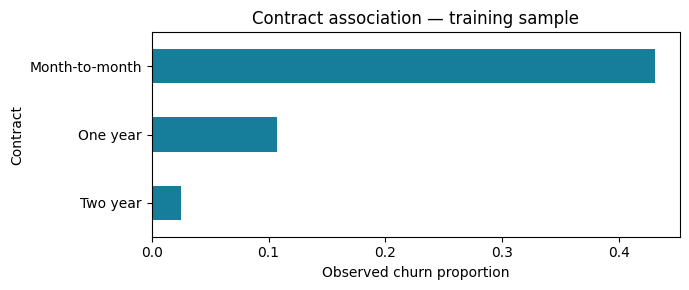

In [3]:
eda = df.loc[X_train.index].assign(churn=y_train)
contract = eda.groupby("Contract").churn.agg(rate="mean", customers="count")
display(contract.round(4))
ax = contract.rate.sort_values().plot.barh(color="#167d9a", figsize=(7, 3))
ax.set(xlabel="Observed churn proportion", title="Contract association — training sample")
plt.tight_layout()
plt.show()

**Lecture :** Les taux diffèrent selon le contrat ; les effectifs précisent le périmètre.

**Interprétation :** Cela motive une vérification de segment, sans prouver qu'allonger le contrat évite le churn.

**Impact :** Comparer ensuite à une règle CRM ; aucune offre recommandée par ce seul graphique.

**Trace :** Calcul sur X_train.index ; figures/customer_patterns.png.

**Contexte :** L'ancienneté pourrait être disponible au scoring.

**Question :** Les distributions diffèrent-elles selon le churn ?

**Notion :** Distribution par classe.

**Risques :** Cohorte récente différente ; absence de dates.

**Mesure :** Médiane, quartiles et histogramme sur train.

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,3104.0,37.52,24.27,0.0,15.0,37.0,61.0,72.0
Yes,1121.0,17.82,19.43,1.0,2.0,10.0,29.0,72.0


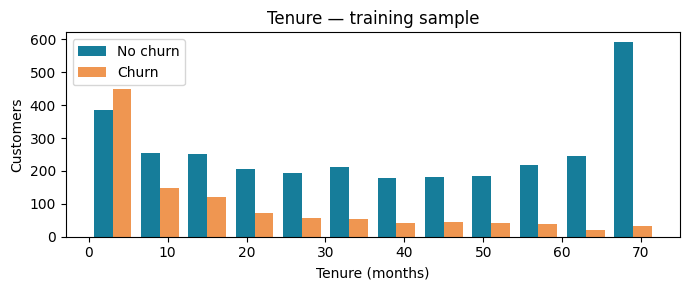

In [4]:
display(eda.groupby("Churn").tenure.describe().round(2))
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist([eda.loc[eda.churn.eq(0), "tenure"], eda.loc[eda.churn.eq(1), "tenure"]],
        bins=12, label=["No churn", "Churn"], color=["#167d9a", "#ef9651"])
ax.set(xlabel="Tenure (months)", ylabel="Customers", title="Tenure — training sample")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture :** Les distributions diffèrent et se chevauchent.

**Interprétation :** Un signal associatif existe ; pas de plafond irréductible démontré.

**Impact :** Étudier le classement ; revenir au nettoyage si une distribution incohérente apparaît.

**Trace :** EDA sur train ; aucun choix opportuniste sur test.

## 7 — Préparation : périmètre et anti-fuite

**Contexte :** Comparer les modèles sur des ensembles distincts.

**Question :** Les transformations apprennent-elles sur les données autorisées ?

**Notion :** Split stratifié, Pipeline et ColumnTransformer.

**Risques :** Imputation sur test ; fuite temporelle métier malgré un pipeline correct.

**Mesure :** Tailles, intersections et variables exclues.

In [5]:
display({"train": len(X_train), "validation": len(X_val), "test": len(X_test)})
assert "customerID" not in X and "Churn" not in X
assert not (set(X_train.index) & set(X_val.index))
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))
print("ID and target excluded; disjoint samples.")
# make_pipeline learns median, scaling and one-hot only during fit.
# fit_candidates fits preprocessing separately inside each CV fold.

{'train': 4225, 'validation': 1409, 'test': 1409}

ID and target excluded; disjoint samples.


**Lecture :** 4 225 train, 1 409 validation, 1 409 test.

**Interprétation :** Fuites de préparation contrôlées ; disponibilité temporelle non vérifiable.

**Impact :** Continuer le benchmark ; fuite détectée → retour préparation / DPD. STOP validation prospective sans dates.

**Trace :** src/analysis.py et tests de médiane train / catégorie inconnue.

## 8 — Baseline / ML : facultatif, justifié par la question

Le classement sous capacité nécessite des scores. Nous comparons deux familles adaptées à une comparaison simple.
Une règle simple suffisante pourrait conduire à abandonner le modèle. Le Dummy est une référence minimale, pas une règle CRM complète.

**Contexte :** Vérifier si les scores ajoutent du signal.

**Question :** Logistique ou forêt améliore-t-elle la référence sur train ?

**Notion :** Baseline et validation croisée cinq plis, ajout de fiabilisation expliqué.

**Risques :** Surinterpréter une petite différence ; non-convergence.

**Mesure :** AUC moyenne, dispersion et average precision des plis.

In [6]:
trained = fit_candidates(X, X_train, y_train)
cv_table, fitted = trained
display(cv_table.round(4))
selected = cv_table.drop(index="Dummy").cv_auc_mean.idxmax()
print("Selected by training CV:", selected)

,cv_auc_mean,cv_auc_sd,cv_ap_mean
model,,,
Dummy,0.5000,0.0000,0.2653
Logistic regression,0.8482,0.0119,0.6668
Random forest,0.8471,0.0119,0.6680


Selected by training CV: Logistic regression


**Lecture :** AUC CV : logistique 0,8482 ; forêt 0,8471 ; Dummy 0,5000.

**Interprétation :** Signal présent ; modèles proches. Le critère préétabli sélectionne la logistique, sans démontrer un gain commercial.

**Impact :** Garder ce comparateur ; aucune recherche exhaustive. La standardisation corrige un risque de non-convergence ; un avertissement de convergence arrête le calcul.

**Trace :** reports/cross_validation.csv ; paramètres fixes.

## 9 — Évaluation / MRT : métriques, volumes, FP/FN, coûts, seuils

**Contexte :** Évaluer sans adapter les paramètres au test.

**Question :** Quels clients sont signalés, avec quelles erreurs ?

**Notion :** Seuil figé sur validation, matrice et top-k.

**Risques :** TP ≠ client sauvé ; FP pas forcément acceptable ; capacité dépassée.

**Mesure :** Test 1 409 clients ; scénarios 0,5, 0,4 et quantile validation ; capacités 10/20/30 %.

,accuracy,roc_auc,average_precision,brier,precision,recall,f1,contacts,tn,fp,fn,tp
model,,,,,,,,,,,,
Dummy,0.7346,0.5000,0.2654,0.1950,0.0000,0.0000,0.0000,0,1035,0,374,0
Logistic regression,0.8013,0.8433,0.6344,0.1376,0.6487,0.5481,0.5942,316,924,111,169,205
Random forest,0.7921,0.8409,0.6455,0.1373,0.6517,0.4652,0.5429,267,942,93,200,174


,policy,threshold,accuracy,roc_auc,average_precision,brier,precision,recall,f1,contacts,tn,fp,fn,tp
0,Default 0.5,0.5000,0.8013,0.8433,0.6344,0.1376,0.6487,0.5481,0.5942,316,924,111,169,205
1,Illustrative 0.4,0.4000,0.7807,0.8433,0.6344,0.1376,0.5747,0.6684,0.6180,435,850,185,124,250
2,Validation capacity 30%,0.3849,0.7771,0.8433,0.6344,0.1376,0.5664,0.6845,0.6199,452,839,196,118,256


,capacity,contacts,churners_captured,precision,recall,lift_vs_random
0,0.1,141,105,0.7447,0.2807,2.8055
1,0.2,282,191,0.6773,0.5107,2.5517
2,0.3,423,246,0.5816,0.6578,2.1910


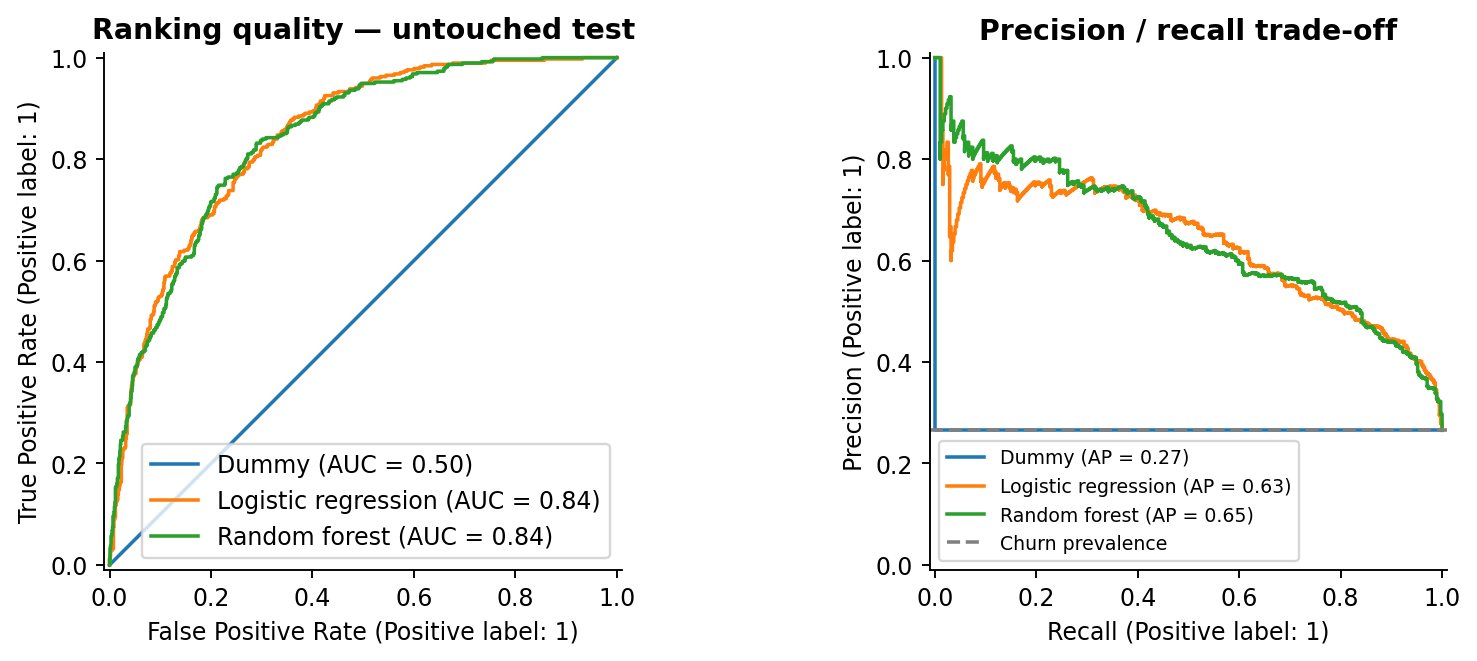

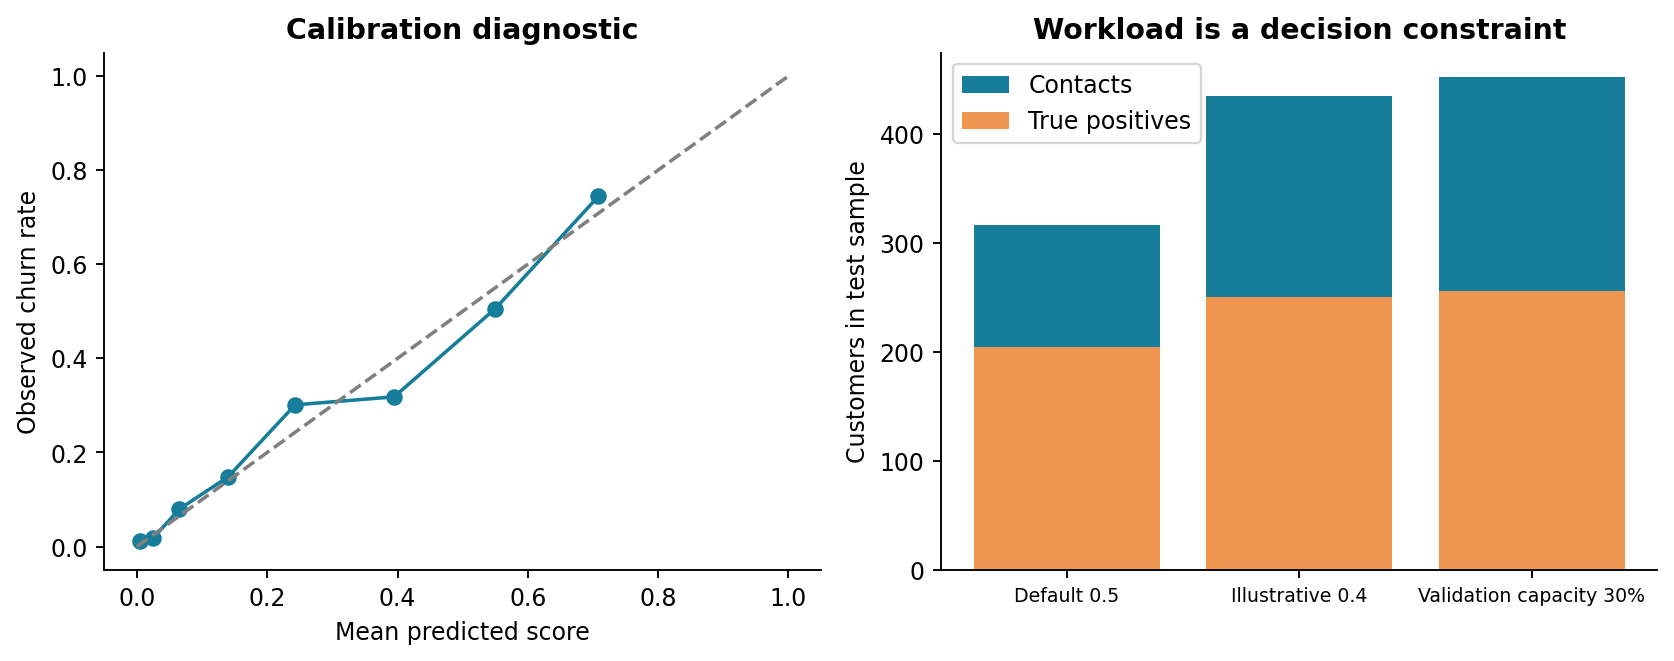

In [7]:
# Reuses already fitted candidates: no retraining or test-based selection.
# run freezes the validation threshold before test evaluation.
result = run(df=df, prepared=prepared, trained=trained)
display(result["test"].round(4))
display(result["thresholds"].round(4))
display(result["capacity"].round(4))
display(Image(filename=str(ROOT / "figures/model_comparison.png")))
display(Image(filename=str(ROOT / "figures/decision_tradeoffs.png")))

**Lecture :** AUC logistique test 0,8433 ; précision 0,6487, rappel 0,5481 à 0,5. Top 30 % : 423 contacts, 246 churners. Seuil validation 0,3849 : 452 contacts, 256 TP, 196 FP, 118 FN.

**Interprétation :** Le seuil atteint 32,1 % sur test. Un quantile appris n'assure pas un plafond transférable. Top-k contrôle le volume, pas la valeur.

**Impact :** MRT incomplète sur les coûts : reporter la campagne. Capacité stricte → classement plafonné après éligibilité.

**Trace :** reports/test_metrics.csv, thresholds.csv, capacity.csv, summary.json ; coûts manquants explicités.

## 10 — Interprétation : faits, hypothèses et incertitudes

**Contexte :** Expliquer les limites d'un score.

**Question :** Que peut-on expliquer sans effet causal inventé ?

**Notion :** Coefficients conditionnels et intervalle d'AUC à modèle fixé.

**Risques :** Coefficients pris pour leviers ; intervalle test pris pour stabilité future.

**Mesure :** Coefficients extrêmes, intervalle bootstrap (complément de lecture).

In [8]:
coefficients = result["coefficients"]
display(coefficients.rename("coefficient").to_frame().iloc[list(range(5)) + list(range(len(coefficients)-5, len(coefficients)))].round(4))
display({"test_auc_bootstrap_95_interval": result["summary"]["test_auc_bootstrap_95_interval"]})

,coefficient
numeric__tenure,-1.3261
categorical__Contract_Two year,-0.8444
categorical__InternetService_DSL,-0.5662
numeric__MonthlyCharges,-0.3301
categorical__MultipleLines_No,-0.3128
categorical__StreamingTV_Yes,0.1749
categorical__PaymentMethod_Electronic check,0.1844
categorical__InternetService_Fiber optic,0.5330
numeric__TotalCharges,0.6014
categorical__Contract_Month-to-month,0.6551


{'test_auc_bootstrap_95_interval': [0.820705330829315, 0.8642455626038372]}

**Lecture :** Intervalle AUC conditionnel ≈ [0,821 ; 0,864]. Coefficients complets exportés.

**Interprétation :** Codage, régularisation et corrélations affectent les coefficients. L'intervalle n'inclut ni incertitude d'entraînement ni dérive. Brier et calibration restent des diagnostics.

**Impact :** Garder score et action distincts. Ces compléments sont des ajouts de révision, pas une maîtrise avancée déjà validée.

**Trace :** reports/logistic_coefficients.csv et docs/methodology.md.

## 11 — Recommandation : tester, reporter ou STOP

**Faits :** données cohérentes après contrôles, classement informatif, erreurs et volumes mesurés.
**Hypothèses :** besoin CRM, éligibilité, capacités illustratives.
**Inconnus :** date de scoring, horizon, coûts, marge, effet des offres, représentativité.

**STOP déploiement ; reporter la campagne.** Poursuivre seulement avec un besoin client confirmé : reconstruire les variables disponibles à la décision, réserver un test temporel, comparer à une règle CRM et mesurer l'effet incrémental avec groupe témoin.

**Contre-exemple :** les clients les plus à risque peuvent être impossibles à retenir ; un groupe à risque modéré peut mieux répondre. AUC élevée ≠ valeur de rétention.

**Retours autorisés :** coût/action modifiés → Gate 0 ; cohorte différente → DPD ; anomalie → Cleaning ; fuite → Préparation ; gain insuffisant → abandon du modèle.
Lire [la synthèse métier](../reports/business_summary.md).

## 12 — Vérification → oral → publication

**Contexte :** Distinguer livrable, fiabilité métier et compétence professionnelle.

**Question :** Le résultat est-il traçable pour revue ?

**Notion :** Trois contrôles distincts.

**Risques :** Assimiler exécution, publication et autonomie.

**Mesure :** Exports, dimensions, comptabilité des erreurs.

In [9]:
assert result["summary"]["rows"] == 7043
assert result["summary"]["split"] == {"train": 4225, "validation": 1409, "test": 1409}
for _, row in result["thresholds"].iterrows():
    assert row.contacts == row.fp + row.tp
    assert row.tn + row.fp + row.fn + row.tp == 1409
assert len(result["cv"]) == 3
display(result["summary"]["versions"])
print("Consistency checks passed; reports and figures regenerated.")

{'python': '3.10.21',
 'numpy': '2.2.5',
 'pandas': '2.2.3',
 'sklearn': '1.5.2',
 'matplotlib': '3.10.0'}

Consistency checks passed; reports and figures regenerated.


**Lecture :** Calcul et exports cohérents ; aucune erreur de convergence.

**Interprétation :** Technique vérifiable ; décisionnel STOP pour agir ; oral à faire par Zaineb.

**Impact :** Présenter une étude reproductible, sans confondre publication et compétence professionnelle validée.

**Trace :** README, tests et méthode documentée ; aucun identifiant client dans les rapports.

### Relecture orale par Zaineb

- Expliquer le besoin et le blocage Gate 0.
- Justifier les 11 montants inconnus, la conservation des clients et le split.
- Lire FP/FN et les volumes sans annoncer des clients sauvés.
- Distinguer classement, calibration et effet d'une offre.
- Donner un contre-exemple et défendre reporter / STOP.

Support de relecture, sans attestation automatique de compétence.